# Agribusiness Data Analysis — Reproducible Notebook

**Student:** SANJAY H H · **USN:** 1MJ24CD041 · **5th Sem CSE (Data Science)** · MVJ College of Engineering, Bengaluru

This notebook supports the Week 1 planning report and responds to evaluator feedback by providing source-backed numerical analysis, a worked forecast-method comparison, reproducible outputs, and explicit limitations.

**Source/data boundary:** the CSV contains selected national crop/aggregate rows transcribed from the supplied DA&FW crop-wise statistics table. The 2025–26 values are Third Advance Estimates. Synthetic price and supply-chain figures below are teaching scenarios, not observed measurements.

## 1. Load and validate the input data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
DATA = ROOT / "crop_statistics_selected_all_india.csv"
if not DATA.exists():
    raise FileNotFoundError("Place this notebook and crop_statistics_selected_all_india.csv in the same folder.")

df = pd.read_csv(DATA)
required = {"agricultural_year", "crop", "area_lakh_hectares", "production_value", "production_unit", "yield_kg_per_hectare", "estimate_status"}
assert required.issubset(df.columns)
assert len(df) == 40, f"Expected 40 selected rows; got {len(df)}"
assert not df.duplicated(["crop", "agricultural_year"]).any()
assert not df[list(required)].isna().any().any()
for c in ["area_lakh_hectares", "production_value", "yield_kg_per_hectare"]:
    df[c] = pd.to_numeric(df[c], errors="raise")
    assert (df[c] >= 0).all()
assert df.loc[df.agricultural_year.eq("2025-26"), "estimate_status"].str.contains("Third Advance Estimate", case=False).all()

print("Rows:", len(df))
print("Selected crop/aggregate groups:", df.crop.nunique())
print("Years:", sorted(df.agricultural_year.unique()))
df.head()

Rows: 40
Selected crop/aggregate groups: 8
Years: ['2021-22', '2022-23', '2023-24', '2024-25', '2025-26']


,agricultural_year,crop,area_lakh_hectares,production_value,production_unit,yield_kg_per_hectare,estimate_status
0,2021-22,Rice,462.79,1294.71,lakh tonnes,2798,As reported in supplied source
1,2022-23,Rice,478.32,1357.55,lakh tonnes,2838,As reported in supplied source
2,2023-24,Rice,478.28,1378.25,lakh tonnes,2882,As reported in supplied source
3,2024-25,Rice,512.67,1501.84,lakh tonnes,2929,As reported in supplied source
4,2025-26,Rice,528.32,1540.24,lakh tonnes,2915,Third Advance Estimate


## 2. Original numerical analysis: maize and total food grains

In [2]:
years = ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26"]
maize = df[df.crop.eq("Maize")].set_index("agricultural_year").loc[years]
first, last = maize.iloc[0], maize.iloc[-1]
maize_metrics = pd.DataFrame([
    {"indicator":"Area (lakh ha)", "start":first.area_lakh_hectares, "end":last.area_lakh_hectares,
     "change_pct":(last.area_lakh_hectares/first.area_lakh_hectares-1)*100},
    {"indicator":"Production (lakh tonnes)", "start":first.production_value, "end":last.production_value,
     "change_pct":(last.production_value/first.production_value-1)*100},
    {"indicator":"Yield (kg/ha)", "start":first.yield_kg_per_hectare, "end":last.yield_kg_per_hectare,
     "change_pct":(last.yield_kg_per_hectare/first.yield_kg_per_hectare-1)*100},
])
maize_metrics.round(2)

,indicator,start,end,change_pct
0,Area (lakh ha),99.58,144.08,44.69
1,Production (lakh tonnes),337.30,550.93,63.34
2,Yield (kg/ha),3387.00,3824.00,12.90


In [3]:
food = df[df.crop.eq("Total Food Grains")].set_index("agricultural_year").loc[years].copy()
food["yoy_change_pct"] = food.production_value.pct_change()*100
food_cagr = ((food.production_value.iloc[-1]/food.production_value.iloc[0])**(1/4)-1)*100
print(f"Total food-grain endpoint change: {(food.production_value.iloc[-1]/food.production_value.iloc[0]-1)*100:.2f}%")
print(f"Descriptive CAGR across four intervals: {food_cagr:.2f}%")
food[["production_value", "yoy_change_pct", "estimate_status"]]

Total food-grain endpoint change: 19.31%
Descriptive CAGR across four intervals: 4.51%


,production_value,yoy_change_pct,estimate_status
agricultural_year,,,
2021-22,3156.16,NaN,As reported in supplied source
2022-23,3296.87,4.458266,As reported in supplied source
2023-24,3322.98,0.791963,As reported in supplied source
2024-25,3577.32,7.653973,As reported in supplied source
2025-26,3765.63,5.263997,Third Advance Estimate


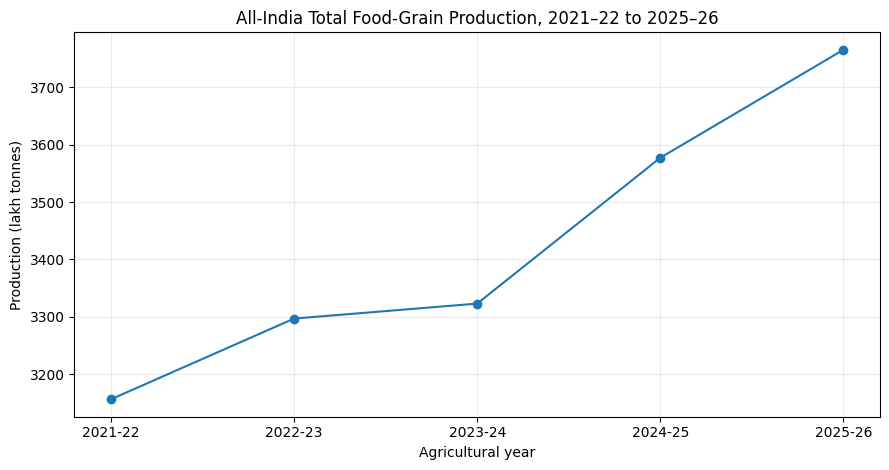

In [4]:
plt.figure(figsize=(9,4.8))
plt.plot(food.index, food.production_value, marker="o")
plt.title("All-India Total Food-Grain Production, 2021–22 to 2025–26")
plt.xlabel("Agricultural year")
plt.ylabel("Production (lakh tonnes)")
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()

**Interpretation:** maize production rises 63.34% from the first to last observation, while area rises 44.69% and reported yield rises 12.90%. Total food-grain production rises 19.31% across the same endpoints. These are descriptive differences, not causal findings. The 2025–26 values are Third Advance Estimates.

## 3. Worked forecast comparison: maize one-step holdout

In [5]:
# Train only on the first four crop years; compare against 2025–26 Third Advance Estimate.
maize_values = maize.production_value.to_numpy(float)
train = maize_values[:-1]
reference = float(maize_values[-1])
forecasts = {
    "Naive baseline": float(train[-1]),
    "Three-year moving average": float(train[-3:].mean()),
    "Linear trend (least squares)": float(np.polyval(np.polyfit(np.arange(len(train)), train, 1), len(train)))
}
rows=[]
for method, estimate in forecasts.items():
    error = reference-estimate
    rows.append({"method":method, "forecast_lakh_tonnes":estimate,
                 "reference_lakh_tonnes":reference, "absolute_error_lakh_tonnes":abs(error),
                 "absolute_percentage_error_pct":abs(error)/abs(reference)*100,
                 "reference_status":"2025–26 Third Advance Estimate"})
forecast_check = pd.DataFrame(rows)
forecast_check.round(2)

,method,forecast_lakh_tonnes,reference_lakh_tonnes,absolute_error_lakh_tonnes,absolute_percentage_error_pct,reference_status
0,Naive baseline,434.09,550.93,116.84,21.21,2025–26 Third Advance Estimate
1,Three-year moving average,397.20,550.93,153.73,27.90,2025–26 Third Advance Estimate
2,Linear trend (least squares),453.76,550.93,97.17,17.64,2025–26 Third Advance Estimate


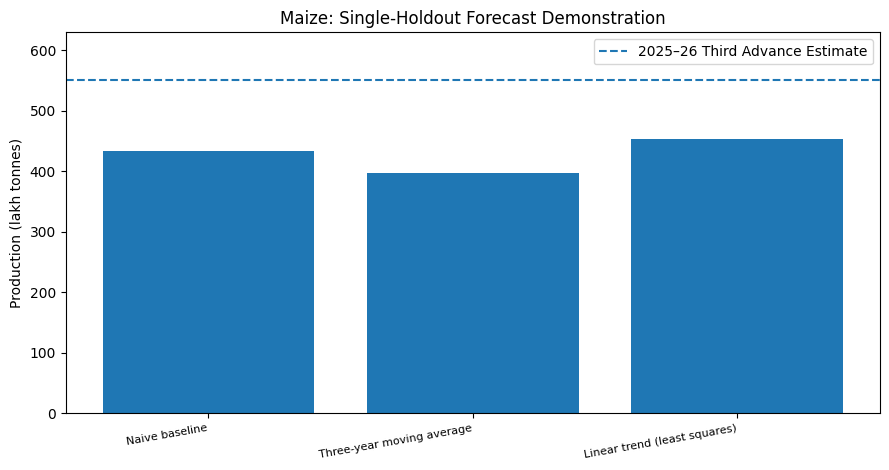

In [6]:
plt.figure(figsize=(9,4.8))
plt.bar(forecast_check.method, forecast_check.forecast_lakh_tonnes)
plt.axhline(reference, linestyle="--", label="2025–26 Third Advance Estimate")
plt.title("Maize: Single-Holdout Forecast Demonstration")
plt.ylabel("Production (lakh tonnes)")
plt.xticks(rotation=10, ha="right", fontsize=8)
plt.ylim(0,630)
plt.legend()
plt.tight_layout()
plt.show()

**Validation limitation:** this comparison uses four training values and one comparison point. The reference is itself an advance estimate. The lower error of the linear trend in this single comparison does not prove it is the best general method. Five annual observations cannot validate a reliable predictive model. A proper next step is to collect a longer consistent series and perform rolling-origin or time-ordered validation over multiple test periods, reporting MAE and RMSE.

## 4. Forward-only food-grain projections (illustrative only)

In [7]:
food_values = food.production_value.to_numpy(float)
food_forecasts = pd.DataFrame([
    {"method":"Naive baseline", "illustrative_2026_27_lakh_tonnes":food_values[-1]},
    {"method":"Three-year moving average", "illustrative_2026_27_lakh_tonnes":food_values[-3:].mean()},
    {"method":"Linear trend (least squares)", "illustrative_2026_27_lakh_tonnes":np.polyval(np.polyfit(np.arange(len(food_values)), food_values, 1), len(food_values))},
])
food_forecasts.round(2)

,method,illustrative_2026_27_lakh_tonnes
0,Naive baseline,3765.63
1,Three-year moving average,3555.31
2,Linear trend (least squares),3873.61


There is no 2026–27 observed result in the input CSV, so these values have no evaluation error. They are method demonstrations, not validated forecasts.

## 5. Hypothetical worked examples — not observed data

In [8]:
# Teaching example only: invented prices, because the supplied crop table contains no market prices.
price_scenario = pd.DataFrame([
    {"stage":"Farm-gate", "price_inr_per_kg":18.0},
    {"stage":"Wholesale", "price_inr_per_kg":24.0},
    {"stage":"Retail", "price_inr_per_kg":32.0},
])
print("Farm-gate-to-retail spread (not profit): ₹", price_scenario.price_inr_per_kg.iloc[-1] - price_scenario.price_inr_per_kg.iloc[0], "/kg")
price_scenario

Farm-gate-to-retail spread (not profit): ₹ 14.0 /kg


,stage,price_inr_per_kg
0,Farm-gate,18.0
1,Wholesale,24.0
2,Retail,32.0


In [9]:
# Teaching example only: stage loss rates are assumed, not measured.
quantity = 1000.0
supply_rows = [{"stage":"Harvested quantity", "input_kg":quantity, "loss_rate_pct":0, "loss_kg":0, "output_kg":quantity}]
for stage, rate_pct in [("Collection",2), ("Storage",4), ("Transport",2)]:
    loss = quantity*rate_pct/100
    output = quantity-loss
    supply_rows.append({"stage":stage,"input_kg":quantity,"loss_rate_pct":rate_pct,"loss_kg":loss,"output_kg":output})
    quantity=output
supply = pd.DataFrame(supply_rows)
print(f"Net assumed loss: {(1000-quantity)/1000*100:.2f}%")
supply.round(3)

Net assumed loss: 7.80%


,stage,input_kg,loss_rate_pct,loss_kg,output_kg
0,Harvested quantity,1000.0,0,0.000,1000.000
1,Collection,1000.0,2,20.000,980.000
2,Storage,980.0,4,39.200,940.800
3,Transport,940.8,2,18.816,921.984


Do not describe these examples as field data. To estimate real spreads or losses, obtain commodity/market/date-specific price and arrival observations, or actual weighed quantities by supply-chain stage. The planned public sources include e-NAM trade details and DA&FW/AGMARKNET sources.

## 6. Run the complete script and inspect outputs

In [10]:
# Optional: execute the full reproducible script from this directory.
# It generates endpoint metrics, year-over-year tables, forecast comparisons,
# an audit CSV, hypothetical example CSVs, a summary text file and PNG charts.
# In a terminal use: python analyze_agri_data.py
from pathlib import Path
sorted(p.name for p in (Path.cwd()/"outputs").glob("*"))

['analysis_summary.txt',
 'data_quality_audit.csv',
 'endpoint_change_metrics.csv',
 'foodgrains_2026_27_illustrative_forecasts.csv',
 'foodgrains_production_trend.png',
 'foodgrains_yoy_analysis.csv',
 'hypothetical_price_spread_scenario.csv',
 'hypothetical_supply_chain_loss_scenario.csv',
 'maize_area_production_yield.png',
 'maize_forecast_holdout.png',
 'maize_forecast_holdout_comparison.csv',
 'production_endpoint_change.png']

## Sources and limitations

- DA&FW selected All-India Crop-wise Area, Production & Yield table supplied with this project; 2025–26 values are Third Advance Estimates.
- Official estimates landing page: https://desagri.gov.in/whats-new-posts/third-advance-estimates-of-production-of-foodgrains-oilseeds-and-other-commercial-crops-for-the-2025-26/
- e-NAM trade details: https://www.enam.gov.in/web/dashboard/trade-data
- India Meteorological Department rainfall information: https://mausam.gov.in/responsive/rainfallinformation_msd.php

This notebook does not contain observed market prices, actual post-harvest losses, farm input costs, or matched water-use data. These require further collection. Basic schema checks cannot guarantee that every value was transcribed correctly; review source rows before final publication.